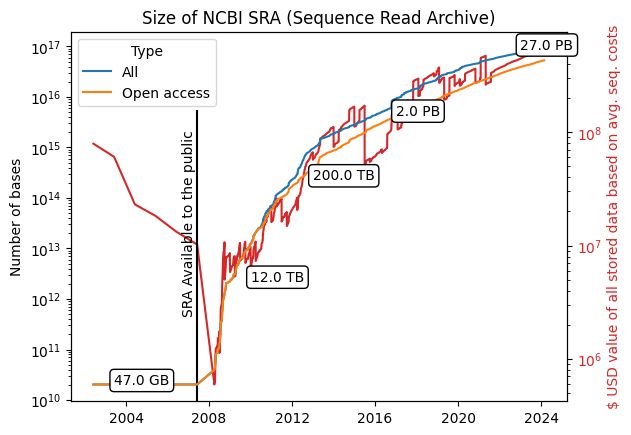

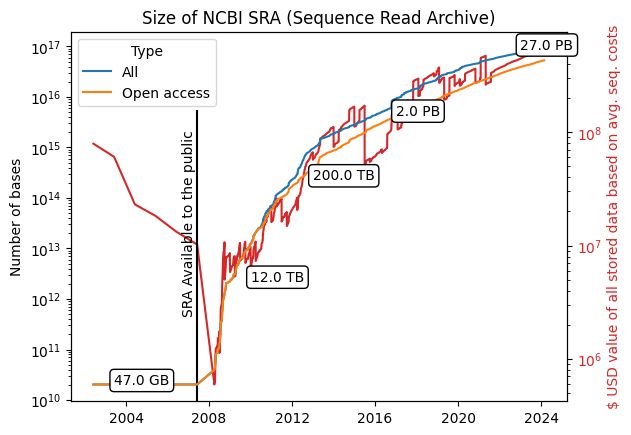

In [154]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import json
import pandas as pd
from datetime import timedelta
#matplotlib.use("pgf")
#matplotlib.rcParams.update({
#    "font.family": "serif",
#    "font.serif": [],
#    "text.usetex": True,
#})

sra_data = pd.read_csv('./sra_stat.csv')
costs_data = pd.read_csv('./genome_seq_costs.csv')
fig, ax = plt.subplots()

costs_data['date'] = pd.to_datetime(costs_data['date'], format='%b-%y')
costs_data = costs_data[(costs_data['date'].dt.year >= 2002)]
costs_data.set_index(['date'],inplace=True)

sra_data['date'] = pd.to_datetime(sra_data['date'], format='%m/%d/%Y')
#sra_data.set_index(['time'],inplace=True)\
sra_data['year'] = pd.DatetimeIndex(sra_data['date']).year
sra_data.set_index(['date'],inplace=True)
sra_data_y = sra_data.drop_duplicates('year', keep='first')

ax.plot(sra_data.index, sra_data.bases, label='All')
ax.plot(sra_data.index, sra_data.open_access_bases, label='Open access')

last_used_val = -100000
rows = list(enumerate(sra_data_y.iterrows()))
for (index, (date, row)) in rows:
    annotation_delta = timedelta(days=365)
    if index > len(rows) - 3:
        annotation_delta = timedelta(days=-365)
    xy = (date + annotation_delta, row['bases'])
    size_val = row['bytes'] / (1024**3)
    if (size_val - last_used_val) > size_val * 0.9:
        last_used_val = size_val
    else:
        continue
    size_unit = "GB"
    if size_val > 1024:
        size_val = size_val/1024
        size_unit = "TB"
    if size_val > 1024:
        size_val = size_val/1024
        size_unit = "PB"
    size_val = int(size_val) / 1
    #ax.annotate(f"{size_val} {size_unit}", xy=xy, textcoords='data')
    t = ax.text(xy[0], xy[1], f"{size_val} {size_unit}", color='black', 
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))

# ax.set_xticks(sra_data.index)

# set the y axis ticks to 10^x
#ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: '{:.0e}'.format(x)))
# set the y axis tick labels to 10^x
#print([str(y) for y in list(ax.get_yticks())])
#ax.set_yticklabels([('$10^{'+str(int(np.log10(y)))+'}$' if y > 0 else "$0$") for y in ax.get_yticks()])
#ax.ticklabel_format(useMathText=True)
ax.set_yscale('log')
#ax.yaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter(useMathText=True))

# US dollar cost per base
total_cost_data_y = []
total_cost_data_x = []
cost_list_date = costs_data.index.to_list()
cost_list_val_mb = costs_data['cost_per_mb_usd'].to_list()
for (index, (date, row)) in list(enumerate(sra_data.iterrows())):
    cur_cost = cost_list_val_mb[0]
    for (l_index, lookup_date) in enumerate(cost_list_date):
        if date >= lookup_date:
            cur_cost = cost_list_val_mb[l_index]
    #total_build_cost = cur_cost # row['bases'] / 1000000 * cur_cost
    total_build_cost = row['bases'] / 1000000 * cur_cost    
    total_cost_data_x.append(date)
    total_cost_data_y.append(total_build_cost)

ax2 = ax.twinx()  # instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('$ USD value of all stored data based on avg. seq. costs', color=color)  # we already handled the x-label with ax1
#ax2.plot(total_cost_data_x, total_cost_data_y, color=color)
ax2.plot(total_cost_data_x, total_cost_data_y, color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_yscale('log')
#fig.tight_layout()  # otherwise the right y-label is slightly clipped

ax2.text(
    #total_cost_data_x[0],
    pd.Timestamp('09/05/2006'),
    total_cost_data_y[0]*0.2, "SRA Available to the public", rotation=90, verticalalignment='center'
)
ax2.vlines(x=pd.Timestamp('06/05/2007'), ymin=0, ymax=total_cost_data_y[0]*2, color = '0')

ax2.set_zorder(10)
ax.set_zorder(11)
ax.patch.set_visible(False)

ax.set_ylabel('Number of bases')
ax.set_title("Size of NCBI SRA (Sequence Read Archive)")
ax.legend(title='Type')

fig

In [97]:
costs_data.index.to_list()

[Timestamp('2008-01-01 00:00:00'),
 Timestamp('2008-04-01 00:00:00'),
 Timestamp('2008-07-01 00:00:00'),
 Timestamp('2008-10-01 00:00:00'),
 Timestamp('2009-01-01 00:00:00'),
 Timestamp('2009-04-01 00:00:00'),
 Timestamp('2009-07-01 00:00:00'),
 Timestamp('2009-10-01 00:00:00'),
 Timestamp('2010-01-01 00:00:00'),
 Timestamp('2010-04-01 00:00:00'),
 Timestamp('2010-07-01 00:00:00'),
 Timestamp('2010-10-01 00:00:00'),
 Timestamp('2011-01-01 00:00:00'),
 Timestamp('2011-04-01 00:00:00'),
 Timestamp('2011-07-01 00:00:00'),
 Timestamp('2011-10-01 00:00:00'),
 Timestamp('2012-01-01 00:00:00'),
 Timestamp('2012-04-01 00:00:00'),
 Timestamp('2012-07-01 00:00:00'),
 Timestamp('2012-10-01 00:00:00'),
 Timestamp('2013-01-01 00:00:00'),
 Timestamp('2013-04-01 00:00:00'),
 Timestamp('2013-07-01 00:00:00'),
 Timestamp('2013-10-01 00:00:00'),
 Timestamp('2014-01-01 00:00:00'),
 Timestamp('2014-04-01 00:00:00'),
 Timestamp('2014-07-01 00:00:00'),
 Timestamp('2014-10-01 00:00:00'),
 Timestamp('2015-01-

In [64]:
508221549585061 / (1000**3)

508.221549585061

In [138]:
pd.Timestamp('06/05/2007')

Timestamp('2007-06-05 00:00:00')

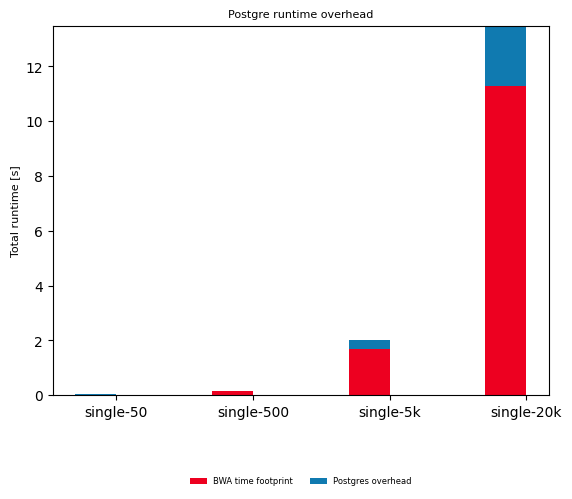

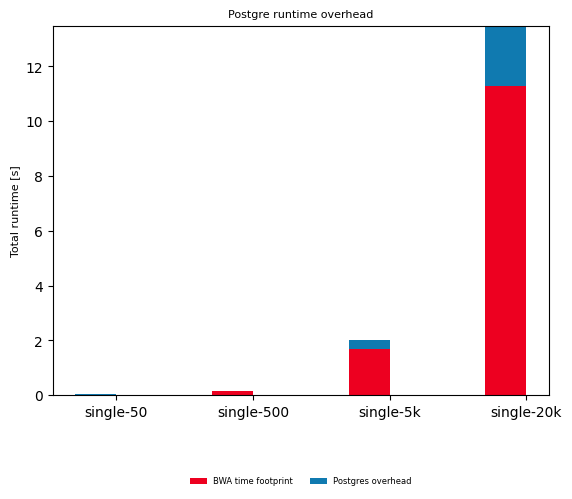

In [166]:
%matplotlib inline

fig, ax = plt.subplots()
#fig.set_size_inches(__LINEWIDTH__, 0.6*__LINEWIDTH__, forward=True)


cases = {
    "single_50": (0.04, 0.02),
    "single_500": (0.15, 0.14),
    "single_5k": (2.01, 1.7),
    "single_20k": (13.49, 11.28),
}

width = 0.3
multiplier = 0
x = np.arange(len(cases))


vals_bwa = [program_stats[0] for program_label, program_stats in cases.items()]
vals_pg = [program_stats[1]-program_stats[0] for program_label, program_stats in cases.items()]

bottom = [0 for case in cases]
for (series, color, name) in [
    (vals_bwa, "#ED0020", "BWA time footprint"),
    (vals_pg, "#107AB0", "Postgres overhead"),
]:
    ax.bar(x, series, width, bottom=bottom, color=color, label=f"{name}")
    bottom = [bottom[i]+series[i] for i in range(len(bottom))]


ax.set_xticks(x + width/2)
ax.set_xticklabels([case.replace('_', '-') for case in cases])
ax.set_ylabel('Total runtime [s]', fontsize=8)
#ax.set_yscale("log")
ax.set_title("Postgre runtime overhead", fontsize=8)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2),
  ncol=2, fancybox=False, shadow=False, prop={'size': 6}, frameon=False)

fig